# Hill Climbing

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.model import Problem
from src.planning import Planner
from src.informed import search
from src.local_search import hill_climbing
from src.csp import solve_csp
from time import perf_counter
problem = Problem(ROOT / 'data_tiny')
t0 = perf_counter()
planner = Planner(problem)
preparation_seconds = perf_counter() - t0
print(f'Preparação comum: {preparation_seconds:.4f} s')
print('Lotes por onda:', [len(w) for w in planner.waves])
print('Valores por domínio:', [len(o) for o in planner.options])

Preparação comum: 0.0037 s
Lotes por onda: [3, 4, 3, 3, 4]
Valores por domínio: [18, 120, 24, 24, 120]


## Procura local: Hill Climbing

A solução inicial é a de Greedy h1. Um vizinho substitui a distribuição e a ordem de **uma** onda, mantendo as restantes. Recalculamos os horários posteriores e rejeitamos soluções que violem qualquer regra. Escolhemos o melhor vizinho de custo estritamente menor; terminamos quando não há melhoria ou após 50 melhorias. Não aceitamos movimentos laterais. A curva inclui a solução inicial na iteração zero.

O resultado é um ótimo local nesta vizinhança; Hill Climbing não garante o ótimo global. Neste ensaio pode coincidir com A*, o que não generaliza para outros dados. O tempo da pesquisa local exclui a obtenção da solução inicial; mostramos também o tempo total Greedy + Hill Climbing.

In [2]:
informed_results = [search(planner, 'greedy', 'h1')]

Histórico de custos (km): [756.61, 709.55, 664.88, 623.24, 598.93, 580.9]
Tempo local: 0.0864 s; com Greedy: 0.1570 s


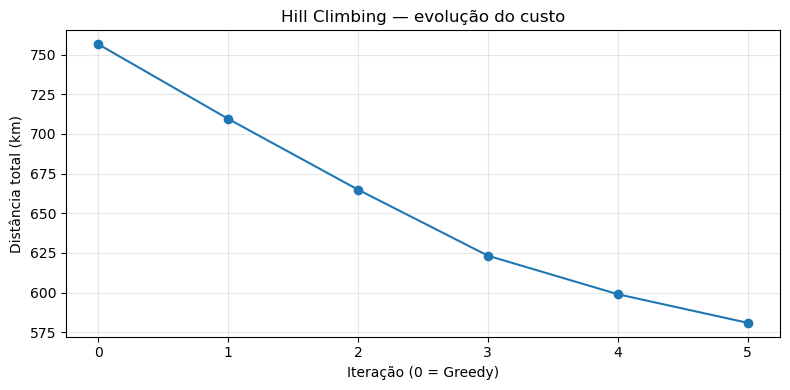

In [3]:
greedy = informed_results[0]
local_result, history = hill_climbing(planner, greedy)
assert problem.validate(local_result.routes).feasible
print('Histórico de custos (km):', [round(x, 2) for x in history])
print(f'Tempo local: {local_result.seconds:.4f} s; com Greedy: {greedy.seconds + local_result.seconds:.4f} s')
plt.figure(figsize=(8, 4))
plt.plot(range(len(history)), history, marker='o')
plt.xlabel('Iteração (0 = Greedy)'); plt.ylabel('Distância total (km)')
plt.title('Hill Climbing — evolução do custo'); plt.xticks(range(len(history)))
plt.grid(alpha=.3); plt.tight_layout(); plt.show()